In [6]:
# Reload sklearn parser modules in case the existing kernel process has cached the unpatched code in RAM
import sys, importlib
if 'sklearn.datasets._arff_parser' in sys.modules:
    importlib.reload(sys.modules['sklearn.datasets._arff_parser'])
if 'sklearn.datasets._openml' in sys.modules:
    importlib.reload(sys.modules['sklearn.datasets._openml'])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

from sklearn.datasets import fetch_openml

mnist = fetch_openml(name = "mnist_784", version = 1, as_frame = False)

X = mnist.data
y = mnist.target.astype(np.uint8)

print("Dataset loaded successfully!")
print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Unique classes:", np.unique(y))
print("Data type:", X.dtype)

Dataset loaded successfully!
Feature shape: (70000, 784)
Target shape: (70000,)
Unique classes: [0 1 2 3 4 5 6 7 8 9]
Data type: int64


In [7]:
X_train = X[:60000]
y_train = y[:60000]

X_test = X[60000:]
y_test = y[60000:]

print("Training data:", X_train.shape)
print("Training labels:", y_train.shape)

print("Testing data:", X_test.shape)
print("Testing labels:", y_test.shape)

Training data: (60000, 784)
Training labels: (60000,)
Testing data: (10000, 784)
Testing labels: (10000,)


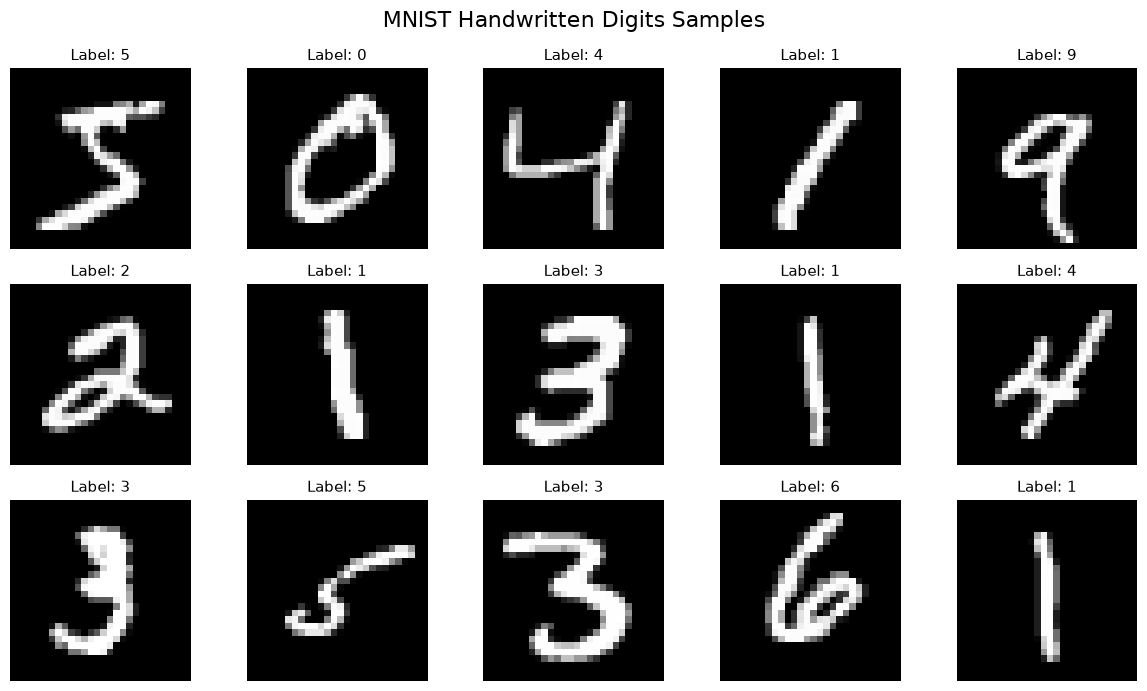

In [8]:
fig,axes = plt.subplots(3, 5, figsize=(12, 7))

for i, ax in enumerate(axes.flat):
    image = X_train[i].reshape(28,28)

    ax.imshow(image, cmap="gray")
    ax.set_title(f"Label: {y_train[i]}", fontsize=11)
    ax.axis("off")

plt.suptitle("MNIST Handwritten Digits Samples", fontsize=16)
plt.tight_layout()
plt.show()

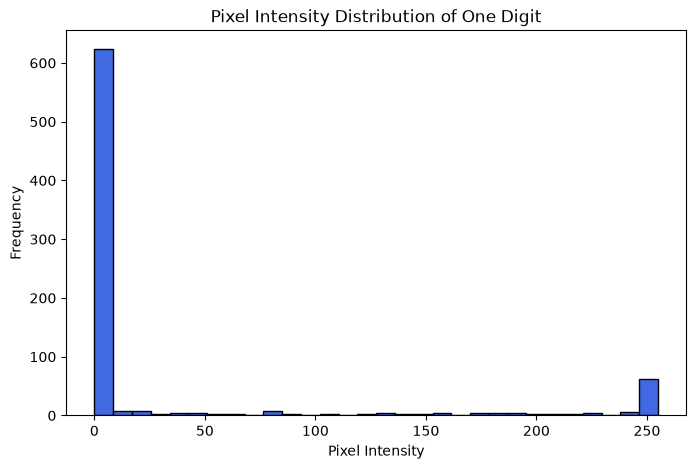

In [9]:
plt.figure(figsize=(8,5))
plt.hist(X_train[0], bins=30, color="royalblue", edgecolor="black")

plt.title("Pixel Intensity Distribution of One Digit")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.show()

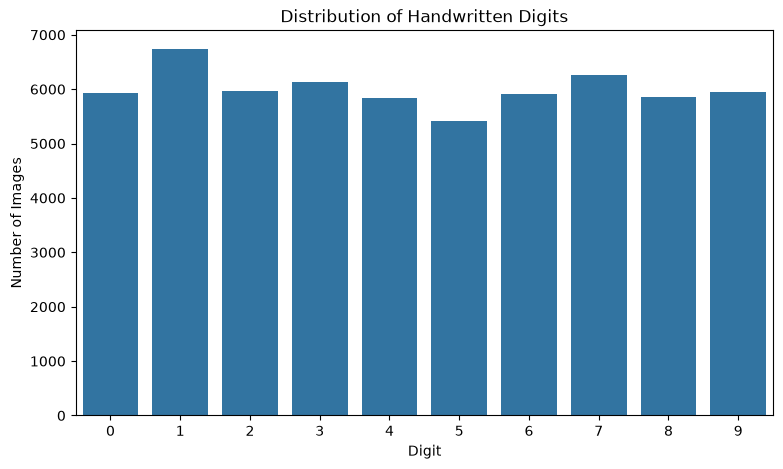

In [10]:
class_counts = pd.Series(y_train).value_counts().sort_index()
plt.figure(figsize=(9,5))
sns.barplot(x = class_counts.index, y = class_counts.values)

plt.title("Distribution of Handwritten Digits")
plt.xlabel("Digit")
plt.ylabel("Number of Images")
plt.show()

In [11]:
sample_image = X_train[0]
print("Image Shape:", sample_image.shape)
print("Minimum pixel value:", sample_image.min())
print("Maximum pixel value:", sample_image.max())

print("\n Pixel Matrix:")
print(sample_image)

Image Shape: (784,)
Minimum pixel value: 0
Maximum pixel value: 255

 Pixel Matrix:
[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   3  18  18  18 126 136 175  26 166 255
 247 127   0   0   0   0   0   0   0   0   0   0   0   0  30  36  94 154
 170 253 253 253 253 253 225 172 253 242 195  64   0   0   0   0   0   0
   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251  93  82
  82  56  39   0   0   0   0   0   0   0

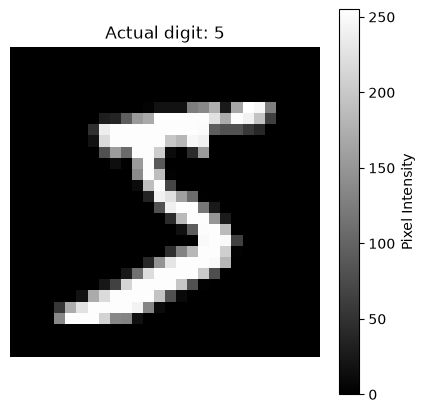

In [14]:
plt.figure(figsize=(5, 5))

plt.imshow(sample_image.reshape(28, 28), cmap="gray")
plt.title(f"Actual digit: {y_train[0]}")
plt.colorbar(label="Pixel Intensity")
plt.axis("off")

plt.show()


Now comes our first actual preprocessing operation.

Remember, MNIST pixel values range from 0 to 255. Feeding these raw values into many ML algorithms can create numerical and optimization difficulties.

We therefore normalize the pixel intensities.

The formula is:
\[
X_{\text{normalized}}=\frac{X}{255}
\]

This transforms every pixel value into the range \([0,1]\).

For example:
Original pixel	Normalized pixel
0	0.000
64	0.251
128	0.502
192	0.753
255	1.000

Why is this useful?
1. Features have a consistent numerical scale.
2. Optimization algorithms can converge more efficiently.
3. It prevents large numerical magnitudes from unnecessarily dominating calculations.
4. It is particularly important for algorithms such as Logistic Regression, SVM and neural networks.

In [ ]:
X_train = X_train.astype("float32")
X_test = X_test.astype("float32")

X_train = X_train/255.0
X_test = X_test/255.0

print("Training data range:", X_train.min(), "to", X_train.max())
print("Testing data range:", X_test.min(), "to", X_test.max())
print("Training data type:", X_train.dtype)

Training data range: 0.0 to 1.0
Training data range: 0.0 to 1.0
Training data type: float32


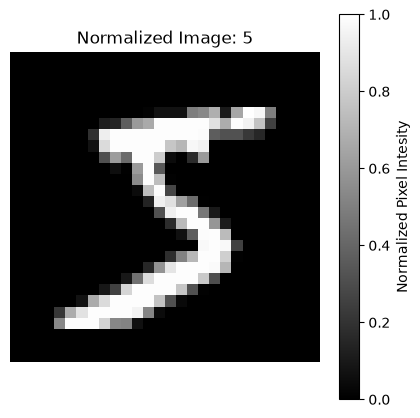

In [18]:
plt.figure(figsize=(5,5))
plt.imshow(X_train[0].reshape(28,28), cmap="gray", vmin=0, vmax=1)
plt.title(f"Normalized Image: {y_train[0]}")
plt.colorbar(label="Normalized Pixel Intesity")
plt.axis("off")
plt.show()

Step 4 — Flattening, feature representation and data preparation
4.1 Understanding the input structure
Remember, our OpenML MNIST dataset has this structure:
\[
X_{\text{train}}\in\mathbb{R}^{60000\times784}
\]

That means:
- 60,000 observations.
- 784 features per observation.
- Each feature represents the intensity of one pixel.
For traditional ML algorithms such as Logistic Regression, SVM and KNN, we generally represent each image as a one-dimensional feature vector.
One handwritten digit
28 × 28
Image matrix

Two-dimensional representation


784
Feature vector

One-dimensional representation



Reshape operation

Same pixel information, different arrangement

Mathematically, flattening converts:
\[
I\in\mathbb{R}^{28\times28}
\]

into:
\[
x\in\mathbb{R}^{784}
\]

The pixels are arranged in a consistent order, usually row by row.

Why does this matter?

Traditional ML algorithms expect a feature matrix of the form:
\[
X =
\begin{bmatrix}
x_{11}&x_{12}&\cdots&x_{1,784}\\
x_{21}&x_{22}&\cdots&x_{2,784}\\
\vdots&\vdots&\ddots&\vdots\\
x_{60000,1}&x_{60000,2}&\cdots&x_{60000,784}
\end{bmatrix}
\]

Each row represents one image, and each column represents one pixel position.

In [19]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

print("Training pixel range:", X_train.min(), X_train.max())
print("Testing pixel range:", X_test.min(), X_test.max())

Training features: (60000, 784)
Testing features: (10000, 784)
Training labels: (60000,)
Testing labels: (10000,)
Training pixel range: 0.0 1.0
Testing pixel range: 0.0 1.0


Understand the target labels
Our feature matrix contains images, but where does the correct answer come from?

That's what y_train provides.

For example:
print("First 15 labels:")print(y_train[:15])



You might see:
[5 0 4 1 9 2 1 3 1 4 3 5 3 6 1]


Each number is the actual digit represented by the corresponding image.

The relationship is:
\[
(X_i,y_i)
\]

Where:
- \(X_i\) = pixel values of an image.
- \(y_i\) = its correct digit label.
This is called supervised learning because the model learns from examples where the correct answers are already provided.

An important distinction: our labels are already integers from 0 to 9. Scikit-learn's Logistic Regression can work directly with these labels. We don't need to convert them into one-hot encoded vectors.

Step 5 — Build our first classification model
We'll start with Logistic Regression.

Wait, isn't Logistic Regression used for regression?

Despite its name, Logistic Regression is a classification algorithm. It estimates class probabilities and assigns an observation to a class.
5.1 How does Logistic Regression classify digits?
Imagine our model receives an image of a handwritten 7.

It examines the 784 pixel values and calculates a score for each possible digit.

For multiclass classification, the model can use the softmax function to convert those scores into probabilities:
\[
P(y=k\mid X)=
\frac{e^{z_k}}{\sum_{j=0}^{9}e^{z_j}}
\]

Here:
- \(z_k\) is the score for class \(k\).
- \(e^{z_k}\) converts the score into a positive value.
- The denominator ensures all ten probabilities sum to 1.
The predicted digit is the class with the highest probability:
\[
\hat y=\arg\max_{k\in\{0,\ldots,9\}}P(y=k\mid X)
\]

For instance, if the model assigns the highest probability to digit 7, it predicts 7.
5.2 Why are we starting with Logistic Regression?
Because it gives us a relatively simple baseline.

It allows us to establish how well a conventional linear classifier can recognize handwritten digits before exploring more sophisticated algorithms.

However, there's a limitation: it learns linear decision boundaries in the 784-dimensional feature space. Handwriting patterns can be much more complicated than that.

Train Logistic Regression

In [23]:
from sklearn.linear_model import LogisticRegression
from time import time
from sklearn.metrics import accuracy_score


logistic_model = LogisticRegression(solver = "lbfgs", max_iter=1000,C=1.0)
start_time = time()
logistic_model.fit(X_train, y_train)
training_time = time() - start_time
print("Training Completed!")
print("Training Time:", round(training_time, 2), "seconds")

Training Completed!
Training Time: 27.86 seconds


Generate predictions

In [24]:
y_pred = logistic_model.predict(X_test)

print("Actual Labels:")
print(y_test[:30])

print("Predicted Labels:")
print(y_pred[:30])

Actual Labels:
[7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4 9 6 6 5 4 0 7 4 0 1]
Predicted Labels:
[7 2 1 0 4 1 4 9 6 9 0 6 9 0 1 5 9 7 3 4 9 6 6 5 4 0 7 4 0 1]


Evaluate accuracy

In [26]:
accuracy = accuracy_score(y_test, y_pred)
print("Model Accuracy:", round(accuracy*100,2), "%")

Model Accuracy: 92.58 %


Detailed model evaluation

Confusion Matrix

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

print("\n Matrix Shape:", cm.shape)

Confusion Matrix:
[[ 958    0    0    4    1    9    4    3    1    0]
 [   0 1110    5    2    0    2    3    2   11    0]
 [   6    9  930   15   10    3   12    9   34    4]
 [   4    1   16  921    1   25    2   10   22    8]
 [   1    3    7    3  920    0    7    5    6   30]
 [   9    2    3   36    8  778   15    6   31    4]
 [   8    3    9    1    7   16  911    2    1    0]
 [   1    7   24    6    6    1    0  949    2   32]
 [   8   11    7   21    8   28   14    9  856   12]
 [   9    8    1    9   21    7    0   22    7  925]]

 Matrix Shape: (10, 10)


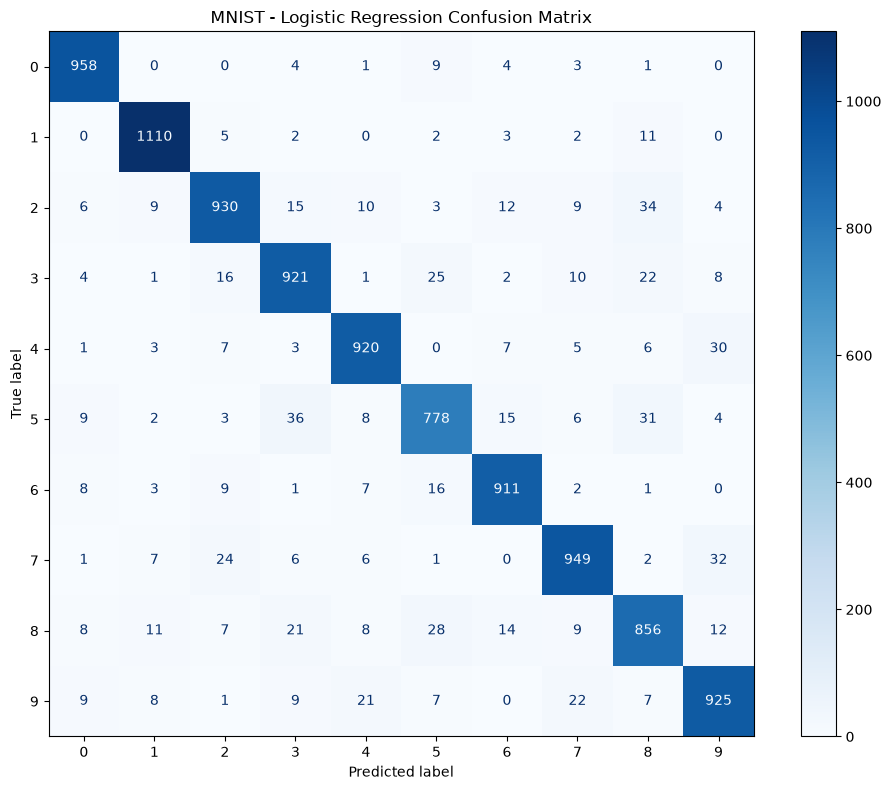

In [30]:
plt.figure(figsize=(10,8))

disp = ConfusionMatrixDisplay( confusion_matrix= cm, display_labels=np.arange(10))
disp.plot(cmap="Blues", values_format="d", ax=plt.gca(),colorbar=True)

plt.title("MNIST - Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

Calculate correct and incorrect predictions per digit

In [33]:
for digits in range(10):
    correct = cm[digits, digits]
    total = cm[digits].sum()
    incorrect = total - correct

    print( f"Digit {digits}: "
        f"Correct = {correct}, "
        f"Incorrect = {incorrect}, "
        f"Total = {total}")

Digit 0: Correct = 958, Incorrect = 22, Total = 980
Digit 1: Correct = 1110, Incorrect = 25, Total = 1135
Digit 2: Correct = 930, Incorrect = 102, Total = 1032
Digit 3: Correct = 921, Incorrect = 89, Total = 1010
Digit 4: Correct = 920, Incorrect = 62, Total = 982
Digit 5: Correct = 778, Incorrect = 114, Total = 892
Digit 6: Correct = 911, Incorrect = 47, Total = 958
Digit 7: Correct = 949, Incorrect = 79, Total = 1028
Digit 8: Correct = 856, Incorrect = 118, Total = 974
Digit 9: Correct = 925, Incorrect = 84, Total = 1009


Precision, Recall and F1-score

In [34]:
from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    y_pred,
    digits=4
)

print(report)

              precision    recall  f1-score   support

           0     0.9542    0.9776    0.9657       980
           1     0.9619    0.9780    0.9699      1135
           2     0.9281    0.9012    0.9145      1032
           3     0.9047    0.9119    0.9083      1010
           4     0.9369    0.9369    0.9369       982
           5     0.8953    0.8722    0.8836       892
           6     0.9411    0.9509    0.9460       958
           7     0.9331    0.9232    0.9281      1028
           8     0.8816    0.8789    0.8802       974
           9     0.9113    0.9167    0.9140      1009

    accuracy                         0.9258     10000
   macro avg     0.9248    0.9247    0.9247     10000
weighted avg     0.9256    0.9258    0.9256     10000



Understanding precision, recall and F1-score
Let's use digit 5 as an example.
Metric	Value	What it means
Precision	89.53%	Of all images predicted as 5, about 89.53% were actually 5
Recall	87.22%	Of all actual 5 images, the model correctly identified 87.22%
F1-score	88.36%	Combined measure of precision and recall

Total Misclassified Images: 742


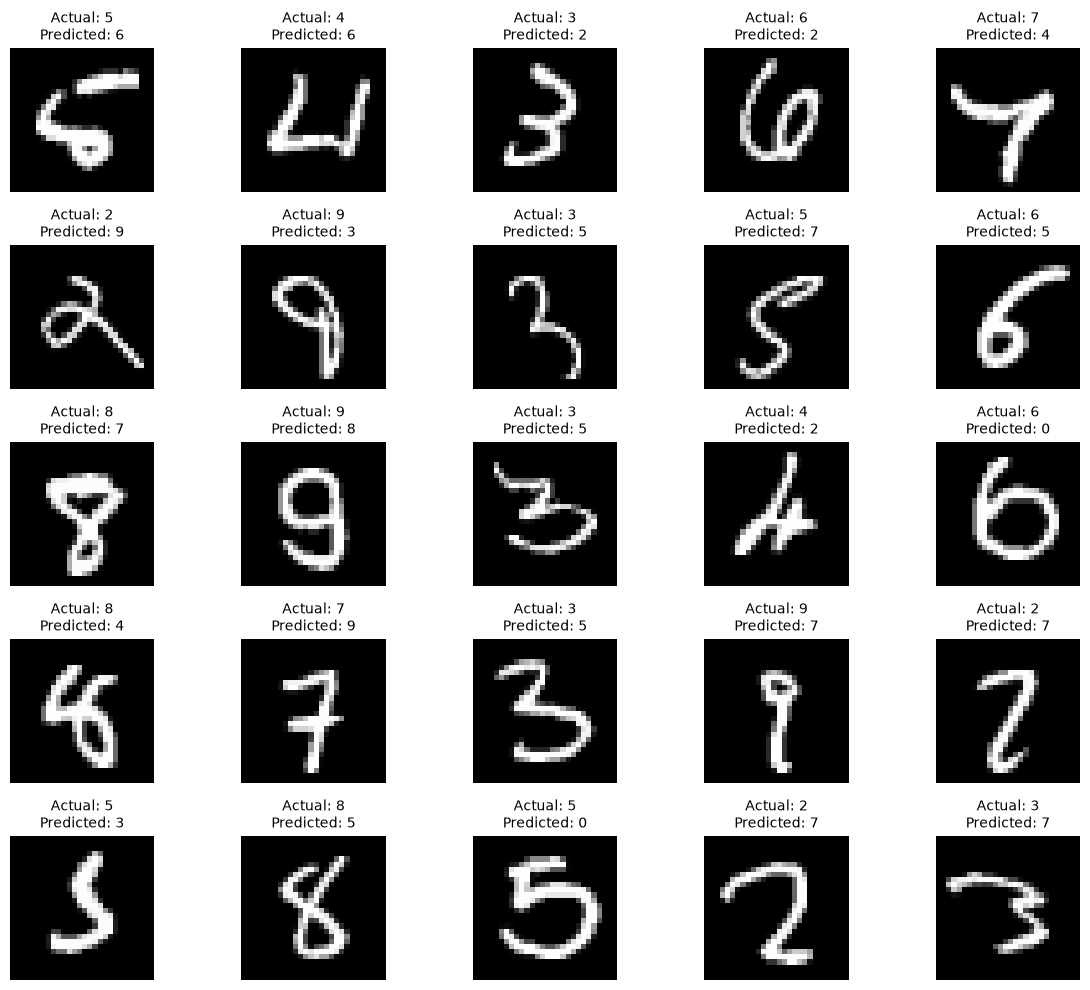

In [41]:
import numpy as np
import matplotlib.pyplot as plt


misclassifies_idx = np.where(y_pred != y_test)[0]
print("Total Misclassified Images:", len(misclassifies_idx))

plt.figure(figsize=(12, 10))

for i, idx in enumerate(misclassifies_idx[:25]):
    plt.subplot(5, 5, i + 1)
    image = X_test[idx].reshape(28, 28)
    plt.imshow(image, cmap="gray")
    plt.title(f"Actual: {y_test[idx]}\nPredicted: {y_pred[idx]}", fontsize=10)
    plt.axis("off")

plt.tight_layout()
plt.show()


In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import precision_score, recall_score, f1_score

digits = np.arange(10)

digit_accuracy = []
for digit in digits:
    actual = (y_test == digit)
    predicted = (y_pred == digit)
    digit_accuracy.append(np.mean(actual == predicted)*100)
    
precision = precision_score(y_test, y_pred, average=None, labels=digits)*100
recall = recall_score(y_test, y_pred, average=None, labels=digits) * 100
f1 = f1_score(y_test, y_pred, average=None, labels=digits) * 100

metrics_df = pd.DataFrame({
    "Digit": digits,
    "Accuracy": digit_accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1
})

print(metrics_df.round(2))

   Digit  Accuracy  Precision  Recall  F1 Score
0      0     99.32      95.42   97.76     96.57
1      1     99.31      96.19   97.80     96.99
2      2     98.26      92.81   90.12     91.45
3      3     98.14      90.47   91.19     90.83
4      4     98.76      93.69   93.69     93.69
5      5     97.95      89.53   87.22     88.36
6      6     98.96      94.11   95.09     94.60
7      7     98.53      93.31   92.32     92.81
8      8     97.67      88.16   87.89     88.02
9      9     98.26      91.13   91.67     91.40


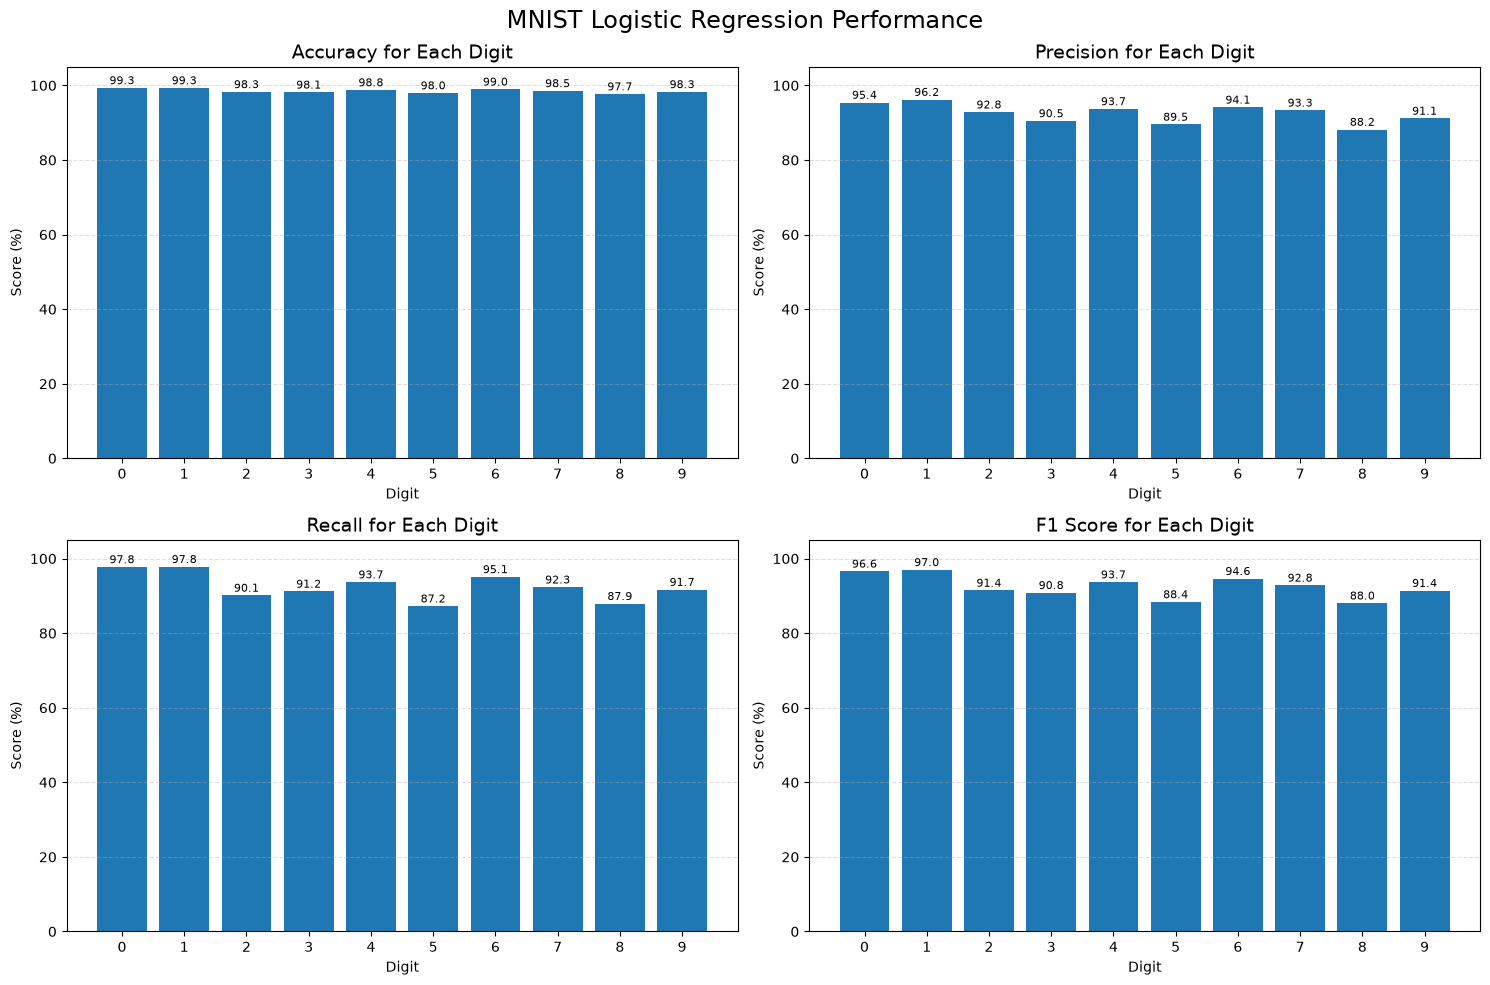

In [44]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, metric in zip(axes.flatten(), metrics):

    values = metrics_df[metric]

    bars = ax.bar(digits, values)

    ax.set_title(f"{metric} for Each Digit", fontsize=14)
    ax.set_xlabel("Digit")
    ax.set_ylabel("Score (%)")
    ax.set_xticks(digits)
    ax.set_ylim(0, 105)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            value + 1,
            f"{value:.1f}",
            ha="center",
            fontsize=8
        )

plt.suptitle(
    "MNIST Logistic Regression Performance",
    fontsize=17
)

plt.tight_layout()
plt.show()

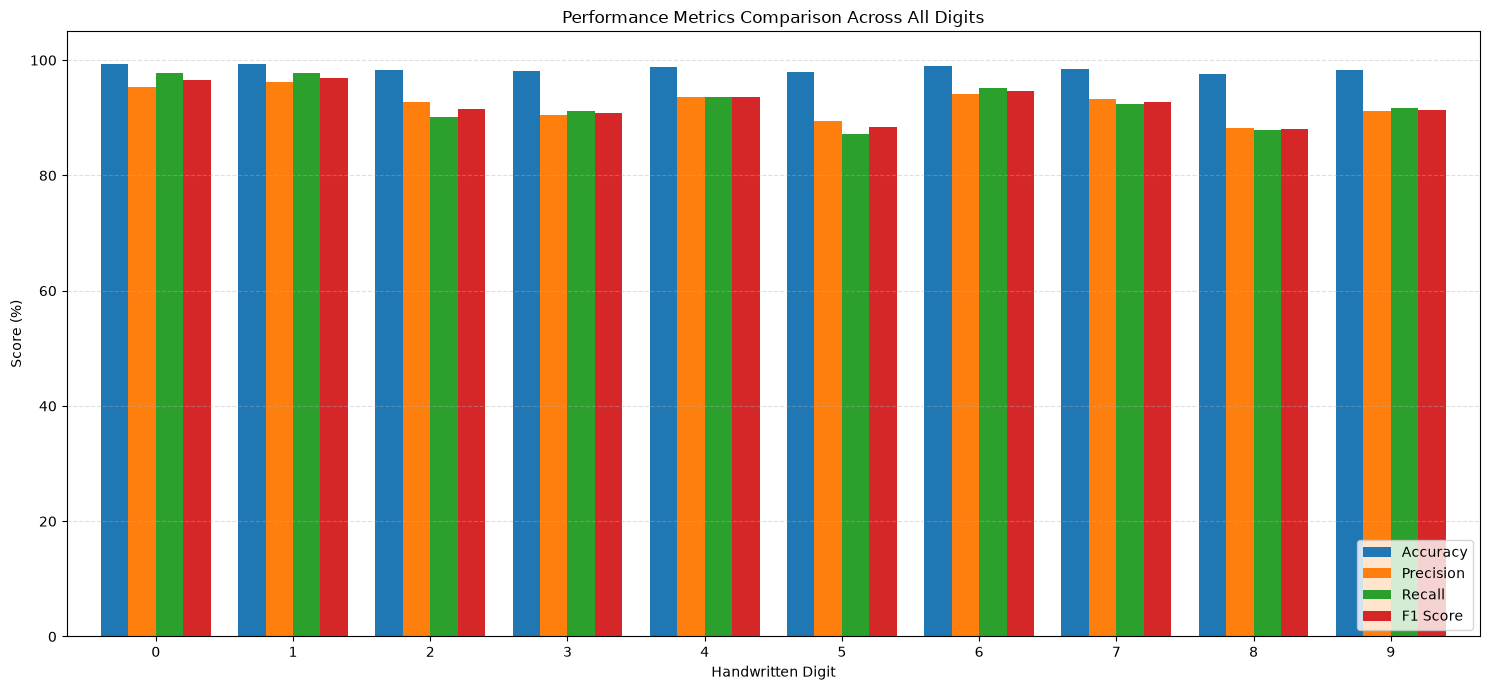

In [45]:
metrics_df.set_index("Digit")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(15, 7),
    width=0.8
)

plt.title("Performance Metrics Comparison Across All Digits")
plt.xlabel("Handwritten Digit")
plt.ylabel("Score (%)")
plt.ylim(0, 105)
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Misclassification analysis

In [54]:
import numpy as np

misclassified_idx = np.where(y_test != y_pred)[0]
errors = pd.DataFrame({
    "Actual": y_test[misclassified_idx],
    "Predicted": y_pred[misclassified_idx]
})

confusion_pairs = (
    errors.groupby(["Actual", "Predicted"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

print("Total incorrect predictions:", len(errors))
print("\nMost common confusion pairs:")
print(confusion_pairs.head(15))

Total incorrect predictions: 742

Most common confusion pairs:
    Actual  Predicted  Count
41       5          3     36
19       2          8     34
62       7          9     32
45       5          8     31
37       4          9     30
68       8          5     28
25       3          5     25
57       7          2     24
28       3          8     22
78       9          7     22
66       8          3     21
76       9          4     21
52       6          5     16
23       3          2     16
14       2          3     15
